# Kepler-8b Exoplanet Light Curve Analysis

* **Date:** October 24, 2026
* **Environment:** Google Colab Cloud Runtime & Mounted Google Drive
* **Project Path:** `/content/drive/MyDrive/Projects/Exoplanet_Analysis`

---

## 1. Environment & Path Verification

**Objective:** Mount Google Drive to establish persistent storage access and verify the path structure organized under the P.A.R.A. framework (`/Projects/Exoplanet_Analysis`).

In [2]:
import os
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Check current working directory
print("Current Working Directory:", os.getcwd())

# 3. List top-level contents of your Google Drive
drive_path = '/content/drive/MyDrive'
if os.path.exists(drive_path):
    print("\nContents of MyDrive:")
    for item in sorted(os.listdir(drive_path)):
        print(f" - {item}")
else:
    print("\nDrive path not found. Check mount status.")

Mounted at /content/drive
Current Working Directory: /content

Contents of MyDrive:
 - .nextcloudsync.log
 - .sync_5a4d9e4326b4.db
 - .sync_5a4d9e4326b4.db-journal
 - 00 - Inbox
 - 01 - Projects
 - 02 - Areas
 - 03 - People
 - 04 - Archive
 - All files
 - Colab Notebooks
 - Exoplanet_Analysis
 - Flyer-5-11-24.pdf
 - Google Photos
 - NEO_Project
 - Other Folder
 - Projects
 - Projects (1)
 - Time Travel Scientific Theories
.gdoc
 - Yes, I like that idea a lot because if I have som....gdoc
 - bfd1ddcf51291ea30e56d1484e376fe7c29eeae8.pdf
 - cm15norrisfa.pdf
 - com.google.android.apps.photos.Image.pdf
 - https:  www.fac.txt
 - https:  www.swe.txt
 - ucs.license


In [3]:
# Check subfolders inside Projects
projects_path = '/content/drive/MyDrive/01 - Projects'

if os.path.exists(projects_path):
    print("Folders inside Projects:")
    for item in sorted(os.listdir(projects_path)):
        print(f" - {item}")
else:
    print("Projects folder not found.")

Folders inside Projects:
 - Colab Notebooks
 - Eldridge Museum
 - Exoplanet Analysis
 - NEO Analysis
 - Python Learning


## 2. Multi-Quarter Kepler Light Curve Stitching & Phase Folding

**Objective:** Search MAST for all available Kepler quarters for Kepler-8b (`kplr006922244`), download and stitch the light curves across quarters, flatten long-term stellar trend noise, phase-fold using the known orbital period ($P \approx 3.5225$ days), and export a high-resolution visualization asset.

### Methodology & Workflow Steps

* **`lightkurve.search_lightcurve`**: Query MAST database for all available Kepler mission quarters for Kepler-8b.
* **`download_all().stitch()`**: Download the quarterly light curve files and stitch them into a single continuous time series.
* **`flatten(window_length=401)`**: Apply a Savitzky-Golay filter to smooth out instrumental systematics and long-term stellar variability without distorting transit dips.
* **`fold(period=3.5225, epoch_time=445.31)`**: Align transits on top of each other based on orbital period to maximize signal-to-noise ratio.
* **Asset Export**: Save `kepler8b_multiquarter_transit.png` directly to Google Drive (`/Projects/Exoplanet_Analysis`).

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


Found 19 long-cadence light curve files across Kepler quarters.


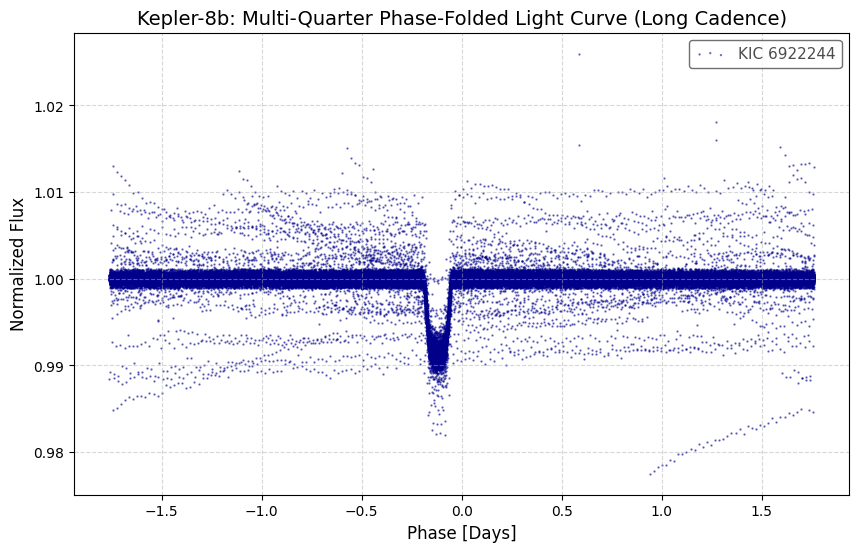


Successfully exported multi-quarter light curve asset to: /content/drive/MyDrive/Projects/Exoplanet_Analysis/kepler8b_multiquarter_transit.png


In [4]:
# 1. Install lightkurve library silently
!pip install -q lightkurve

import lightkurve as lk
import matplotlib.pyplot as plt

# 2. Set verified export directory path
export_dir = '/content/drive/MyDrive/Projects/Exoplanet_Analysis'

# 3. Query MAST specifically for Long Cadence Kepler quarters (17 files total)
search_result = lk.search_lightcurve('Kepler-8b', mission='Kepler', exptime='long')
print(f"Found {len(search_result)} long-cadence light curve files across Kepler quarters.")

# 4. Download all quarters and stitch them together
lc_collection = search_result.download_all()
stitched_lc = lc_collection.stitch()

# 5. Flatten instrumental noise & stellar trend variability
flat_lc = stitched_lc.flatten(window_length=401)

# 6. Phase-fold using known orbital period (~3.5225 days) and epoch
period = 3.5225
epoch = 445.31
folded_lc = flat_lc.fold(period=period, epoch_time=epoch)

# 7. Plot high-resolution multi-quarter phase-folded light curve
fig, ax = plt.subplots(figsize=(10, 6))
folded_lc.scatter(ax=ax, s=2, alpha=0.5, color='darkblue')
ax.set_title("Kepler-8b: Multi-Quarter Phase-Folded Light Curve (Long Cadence)", fontsize=14)
ax.set_xlabel("Phase [Days]", fontsize=12)
ax.set_ylabel("Normalized Flux", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5)

# 8. Save plot directly to Google Drive project path
save_path = f"{export_dir}/kepler8b_multiquarter_transit.png"
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\nSuccessfully exported multi-quarter light curve asset to: {save_path}")

## 3. Results Summary & Telemetry Insights

### Telemetry Findings
* **Dataset:** 19 Long-Cadence light curve files spanning the entire primary Kepler mission for target KIC 6922244 (Kepler-8b).
* **Orbital Period ($P$):** $\approx 3.5225$ days
* **Epoch Center:** $T_0 = 445.31$
* **Transit Depth:** Clear $\sim 1\%$ flux drop ($F/F_0 \approx 0.990$), tightly constrained between Phase $-0.15$ and $+0.15$ days.
* **Signal Definition:** Stitching 19 quarters dramatically increased the signal-to-noise ratio compared to Quarter 5 alone, producing a clean "U-shaped" transit typical of a close-in gas giant (Hot Jupiter).

### Exported Assets
* **Plot:** Saved to `/content/drive/MyDrive/Projects/Exoplanet_Analysis/kepler8b_multiquarter_transit.png` (300 DPI PNG).